# diff/nrgs_hypothesis_heads — what does each query-content hypothesis's mask select?

One head-level NRGS query mask was trained per hypothesis (`scripts/diff/train_nrgs_mask.py`, design
doc `agent_reports/claude/analysis/q_transfer_query_content_hypotheses_design.md`). Each mask is a
(layer × head) grid of values in [0, 1]; the transplant at DST's last token is
`m·q_src + (1−m)·q_dst` per head, trained so the patched next token becomes that hypothesis's letter.
This notebook loads every mask **from disk only** (no model weights — `AutoConfig` supplies
`n_layer` / `n_heads`), shows the mask landscape and the selected heads, compares the hypotheses,
and (optionally) exports a selection as a head-set json.

| run | target | data | training |
|---|---|---|---|
| `H1 od1` | set progress (`order_diff_1` only) | `order_diff` | 50 epochs, λ 20 |
| `H1 mix λ20` / `λ50` | set progress (the 6 H1 configs) | `mixed` | 10 epochs |
| `H1c` | count progress | `h1c` | 10 epochs, λ 20 |
| `H2` | order id | `h2` (int only) | 10 epochs, λ 20 — **only ~40 optimizer steps** |
| `H3` | induction ("I follow x") | `h3` | 10 epochs, λ 20 |

References: `goal-250` (the paper's goal heads) and `ctrl-250` (later-half control) as fixed 0/1 sets.

Caveats the tables surface:
* **"learned mask" vs "learned head set"** — the training script's final eval reports the *soft* mask
  (every head, weighted by m) and the *binarized* one (m = 1 for heads > 0.9 **inside layers 25–56**,
  0 elsewhere). The exported `head_sets/*.json` use all layers. `CFG` below lets you pick either rule.
* **saturation** — masks clamp to [0, 1] and many heads sit at exactly 1.0 (`n_sat`); a top-k below
  that count cuts through a tie block.
* **H2 never sparsified** (every head > 0.5): too few optimizer steps. Its selection is where the mask
  stopped, not a localization.
* **Not all H1 configs isolate set progress** — in `om1` / `om2` / `dvp1` every hypothesis predicts the
  same letter (see the design doc).

In [1]:
%load_ext autoreload
%autoreload 2
import os, sys, json, logging, itertools
sys.path.append("../..")
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ.setdefault("HF_HUB_OFFLINE", "1")

import numpy as np
import torch
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from dataclasses import dataclass, field
from pathlib import Path
from collections import Counter
from rich.console import Console
from rich.theme import Theme
from rich.table import Table
from rich.box import SIMPLE_HEAVY
from src.utils import logging_utils, env_utils

logging_utils.configure(level=logging.WARNING)
logger = logging.getLogger(__name__)
console = Console(theme=Theme({"default": "white"}), highlight=False, width=200)
def rich_print(*a, **k): console.print(*a, **k)
RES = env_utils.DEFAULT_RESULTS_DIR
REPO = Path(os.path.dirname(RES))
RES

'/disk/u/arnab/Codes/Projects/goals/results'

In [2]:
# ── model geometry only: no weights are loaded, so this notebook needs no GPU ──
from transformers import AutoConfig

MODEL_NAME = "Qwen/Qwen2.5-Coder-32B-Instruct"
SLUG = MODEL_NAME.split("/")[-1]
_cfg = AutoConfig.from_pretrained(MODEL_NAME)
N_LAYER = _cfg.num_hidden_layers
N_HEADS = _cfg.num_attention_heads
MASK_ROOT = Path(RES) / "nrgs_mask" / SLUG
print(f"{SLUG}: n_layer={N_LAYER}  n_heads={N_HEADS}  ({N_LAYER * N_HEADS} heads total)")
print("mask runs on disk:", *sorted(p.name for p in MASK_ROOT.iterdir() if (p / "mask.pt").exists()), sep="\n  ")

Qwen2.5-Coder-32B-Instruct: n_layer=64  n_heads=40  (2560 heads total)
mask runs on disk:
  h1c__python-python__L0-64__lam20__kl1_dir1_ctrl0__logistic__s0
  h2__python-python__L0-64__lam20__kl1_dir1_ctrl0__logistic__s0
  h3__python-python__L0-64__lam20__kl1_dir1_ctrl0__logistic__s0
  mixed__python-python__L0-64__lam20__kl1_dir1_ctrl0__logistic__s0
  mixed__python-python__L0-64__lam50__kl1_dir1_ctrl0__logistic__s0
  order_diff__python-python__L0-64__lam20__kl1_dir1_ctrl0__logistic__s0


In [3]:
# ── per-run config — edit here, everything downstream follows ───────────────
# run:       the results/nrgs_mask/<model>/<run> dir (mask.pt inside)
# selection: give EXACTLY ONE of `threshold` or `topk`.
#   threshold + band=None      -> mask > threshold over ALL layers   (= the exported head_sets/*.json)
#   threshold + band=(25, 56)  -> mask > threshold inside the band   (= the final eval's "learned_bin")
#   topk                       -> the k largest mask values, globally (band must be None)
_RUN = "__python-python__L0-64__lam{lam}__kl1_dir1_ctrl0__logistic__s0"
CFG = {
    "H1 od1":     dict(run="order_diff" + _RUN.format(lam=20), threshold=0.9, topk=None, band=None),
    "H1 mix λ20": dict(run="mixed" + _RUN.format(lam=20),      threshold=0.9, topk=None, band=None),
    "H1 mix λ50": dict(run="mixed" + _RUN.format(lam=50),      threshold=0.9, topk=None, band=None),
    "H1c":        dict(run="h1c" + _RUN.format(lam=20),        threshold=0.9, topk=None, band=None),
    "H2":         dict(run="h2" + _RUN.format(lam=20),         threshold=0.9, topk=None, band=None),
    "H3":         dict(run="h3" + _RUN.format(lam=20),         threshold=0.9, topk=None, band=None),
}
# fixed reference head sets (0/1 grids)
REF = {
    "goal-250": REPO / "head_sets" / SLUG / "goal_topk" / "goal__lam20_top250.json",
    "ctrl-250": REPO / "head_sets" / SLUG / "control" / "control250__laterhalf.json",
}
COLOR = {                         # one matte tone per hypothesis
    "H1 od1": "#BF625E", "H1 mix λ20": "#C2894B", "H1 mix λ50": "#D9A86C",
    "H1c": "#5E7CBF", "H2": "#7E6BA8", "H3": "#5E9E72",
    "goal-250": "#4A4A4A", "ctrl-250": "#9AA0A6",
}

In [4]:
# ── loaders: each returns the full mask grid + the selection under its cfg ──
@dataclass
class HeadSet:
    name: str
    grid: np.ndarray            # (N_LAYER, N_HEADS) mask values (NaN = not a candidate)
    selected: list              # [(layer, head)]
    rule: str
    provenance: str
    cfg: dict = field(default_factory=dict)
    final_eval: dict = field(default_factory=dict)
    train_cfg: dict = field(default_factory=dict)

    @property
    def key(self):
        return set(map(tuple, self.selected))


def _validate(name, c):
    if (c.get("threshold") is None) == (c.get("topk") is None):
        raise ValueError(f"{name}: give exactly one of threshold / topk")
    if c.get("topk") is not None and c.get("band") is not None:
        raise ValueError(f"{name}: topk ranks globally — band must be None")
    return c


def _select(grid, c):
    g = np.nan_to_num(grid, nan=-1.0)
    if c.get("topk") is not None:
        flat = np.argsort(-g, axis=None, kind="stable")[: int(c["topk"])]
        return [tuple(map(int, np.unravel_index(i, g.shape))) for i in flat], f"top-{c['topk']} (global)"
    lo, hi = c["band"] if c.get("band") else (0, N_LAYER)
    sel = [(int(l), int(h)) for l, h in np.argwhere(g > c["threshold"]) if lo <= l < hi]
    return sel, f"> {c['threshold']:g}" + (f" in L{lo}-{hi}" if c.get("band") else " (all layers)")


def load_mask(name, cfg=None):
    c = _validate(name, dict(cfg or CFG[name]))
    p = MASK_ROOT / c["run"] / "mask.pt"
    ck = torch.load(p, map_location="cpu", weights_only=False)
    grid = np.full((N_LAYER, N_HEADS), np.nan)
    mv = ck["mask_values"].numpy()                       # saved full depth (rows = layers)
    grid[ck["layers"]] = mv[ck["layers"]]
    sel, rule = _select(grid, c)
    return HeadSet(name, grid, sel, rule, f"{c['run']}/mask.pt", c, ck.get("final_eval") or {}, ck.get("config", {}))


def load_ref(name):
    heads = [tuple(map(int, x)) for x in json.loads(Path(REF[name]).read_text())]
    grid = np.zeros((N_LAYER, N_HEADS))
    for l, h in heads:
        grid[l, h] = 1.0
    return HeadSet(name, grid, heads, "fixed set", str(Path(REF[name]).relative_to(REPO)))


SETS = {}
for n in CFG:
    try:
        SETS[n] = load_mask(n)
    except Exception as e:
        rich_print(f"[red]{n}: {type(e).__name__}: {e}[/red]")
for n in REF:
    try:
        SETS[n] = load_ref(n)
    except Exception as e:
        rich_print(f"[red]{n}: {type(e).__name__}: {e}[/red]")
HYPS = [n for n in SETS if n in CFG]
list(SETS)

['H1 od1',
 'H1 mix λ20',
 'H1 mix λ50',
 'H1c',
 'H2',
 'H3',
 'goal-250',
 'ctrl-250']

## 1. Summary — mask statistics and the training script's final eval (val)

`soft` = the learned mask as trained (every head weighted by m); `bin` = m = 1 for heads > 0.9 in
layers 25–56; `goal` / `ctrl` = the fixed 250-head sets under the same transplant. `·′` columns use the
SRC′ query (same frontier, one fewer task done) where the config defines one — a flip that survives
SRC′ is not carried by the done-state. `mass` = Σm (the "effective number" of fully-patched heads).

In [5]:
def _fe(hs, variant, role="src"):
    for k, v in hs.final_eval.items():
        if k.startswith(variant) and k.endswith(f"|{role}"):
            return v
    return None

def _f(v):
    return "—" if v is None else f"{v['flip']:.2f}"

t = Table(title=f"head-level NRGS masks · {SLUG}", box=SIMPLE_HEAVY, pad_edge=False, title_justify="left")
for c_ in ["run", "val n", "steps", ">0", ">0.5", ">0.9", "=1", "mass", "selected", "layers",
           "soft", "soft′", "bin", "bin′", "goal", "goal′", "ctrl"]:
    t.add_column(c_, justify="left" if c_ == "run" else "right", no_wrap=True)
for n in HYPS:
    hs = SETS[n]
    g = hs.grid[np.isfinite(hs.grid)]
    tc = hs.train_cfg
    steps = tc.get("epochs", 0) * -(-tc.get("n_train", 0) // max(1, tc.get("batch_size", 64)))
    ls = sorted({l for l, _ in hs.selected})
    soft = _fe(hs, "learned_soft")
    t.add_row(n, str(soft["n"] if soft else "—"), str(steps), str(int((g > 0).sum())), str(int((g > 0.5).sum())),
              str(int((g > 0.9).sum())), str(int((g >= 0.999).sum())), f"{g.sum():.0f}",
              f"{len(hs.selected)}", f"{ls[0]}-{ls[-1]}" if ls else "—",
              _f(soft), _f(_fe(hs, "learned_soft", "src_ctrl")),
              _f(_fe(hs, "learned_bin")), _f(_fe(hs, "learned_bin", "src_ctrl")),
              _f(_fe(hs, "goal")), _f(_fe(hs, "goal", "src_ctrl")), _f(_fe(hs, "ctrl")))
rich_print(t)
rich_print("[grey58]`steps` = optimizer steps (epochs × ceil(n_train / batch)); with lr 1e-2 a head needs "
           "~100 steps to fall from 1 to 0, so a run with far fewer steps (H2) has not sparsified. "
           "`selected` follows CFG (default: > 0.9, all layers = the exported head sets).[/grey58]")

# per-config breakdown of the soft mask's val flip
rows = {n: (_fe(SETS[n], "learned_soft") or {}).get("by_config", {}) for n in HYPS}
cfgs = sorted({c for r in rows.values() for c in r})
t = Table(title="soft-mask val flip by config", box=SIMPLE_HEAVY, pad_edge=False, title_justify="left")
t.add_column("run", no_wrap=True)
for c_ in cfgs:
    t.add_column(c_, justify="right", no_wrap=True)
for n in HYPS:
    if rows[n]:                                  # older runs (H1 od1) saved no per-config breakdown
        t.add_row(n, *[f"{rows[n][c]['flip']:.2f} ({rows[n][c]['n']})" if c in rows[n] else "" for c in cfgs])
rich_print(t)

head-level NRGS masks · Qwen2.5-Coder-32B-Instruct                                                                                   
                                                                                                                                     
 run          val n   steps     >0   >0.5   >0.9    =1   mass   selected   layers   soft   soft′    bin   bin′   goal   goal′   ctrl 
 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 
 H1 od1         172     600    558    396    265   220    392        265     0-62   0.80    0.16   0.66   0.12   0.37    0.30   0.02 
 H1 mix λ20    1126     710    570    348    225   175    351        225     0-63   0.63    0.10   0.40   0.07   0.43    0.33   0.00 
 H1 mix λ50    1126     710    332    217    140   117    219        140    25-63   0.54    0.10   0.35   0.06   0.43    0.33   0.00 
 H1c            375     240    856    487    267   213    488        267     3-63   0.62    0.02   0.43   0.03   0.33    0.25   0.01 
 H2             108      40   2560   2560    554   327   1891        554     0-63   0.39       —   0.37      —   0.31       —   0.00 
 H3             354     240    802    452    247   197    465        247     3-63   0.69       —   0.45      —   0.49       —   0.01

`steps` = optimizer steps (epochs × ceil(n_train / batch)); with lr 1e-2 a head needs ~100 steps to fall from 1 to 0, so a run with far fewer steps (H2) has not sparsified. `selected` follows CFG 
(default: > 0.9, all layers = the exported head sets).

soft-mask val flip by config                                                                                                                                                              
                                                                                                                                                                                          
 run          diff_vs_prog_1        h1c_1        h1c_2        h2_1        h2_2         h3_1         h3_2   order_diff_1   order_diff_2   order_diff_3   order_matched_1   order_matched_2 
 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 
 H1 mix λ20       0.62 (185)                                                                                 0.68 (191)     0.35 (185)     0.58 (185)        0.82 (192)        0.74 (188) 
 H1 mix λ50       0.52 (185)                                                                                 0.58 (191)     0.31 (185)     0.48 (185)        0.73 (192)        0.62 (188) 
 H1c                           0.70 (189)   0.54 (186)                                                                                                                                    
 H2                                                      0.36 (53)   0.42 (55)                                                                                                            
 H3                                                                              0.68 (178)   0.70 (176)

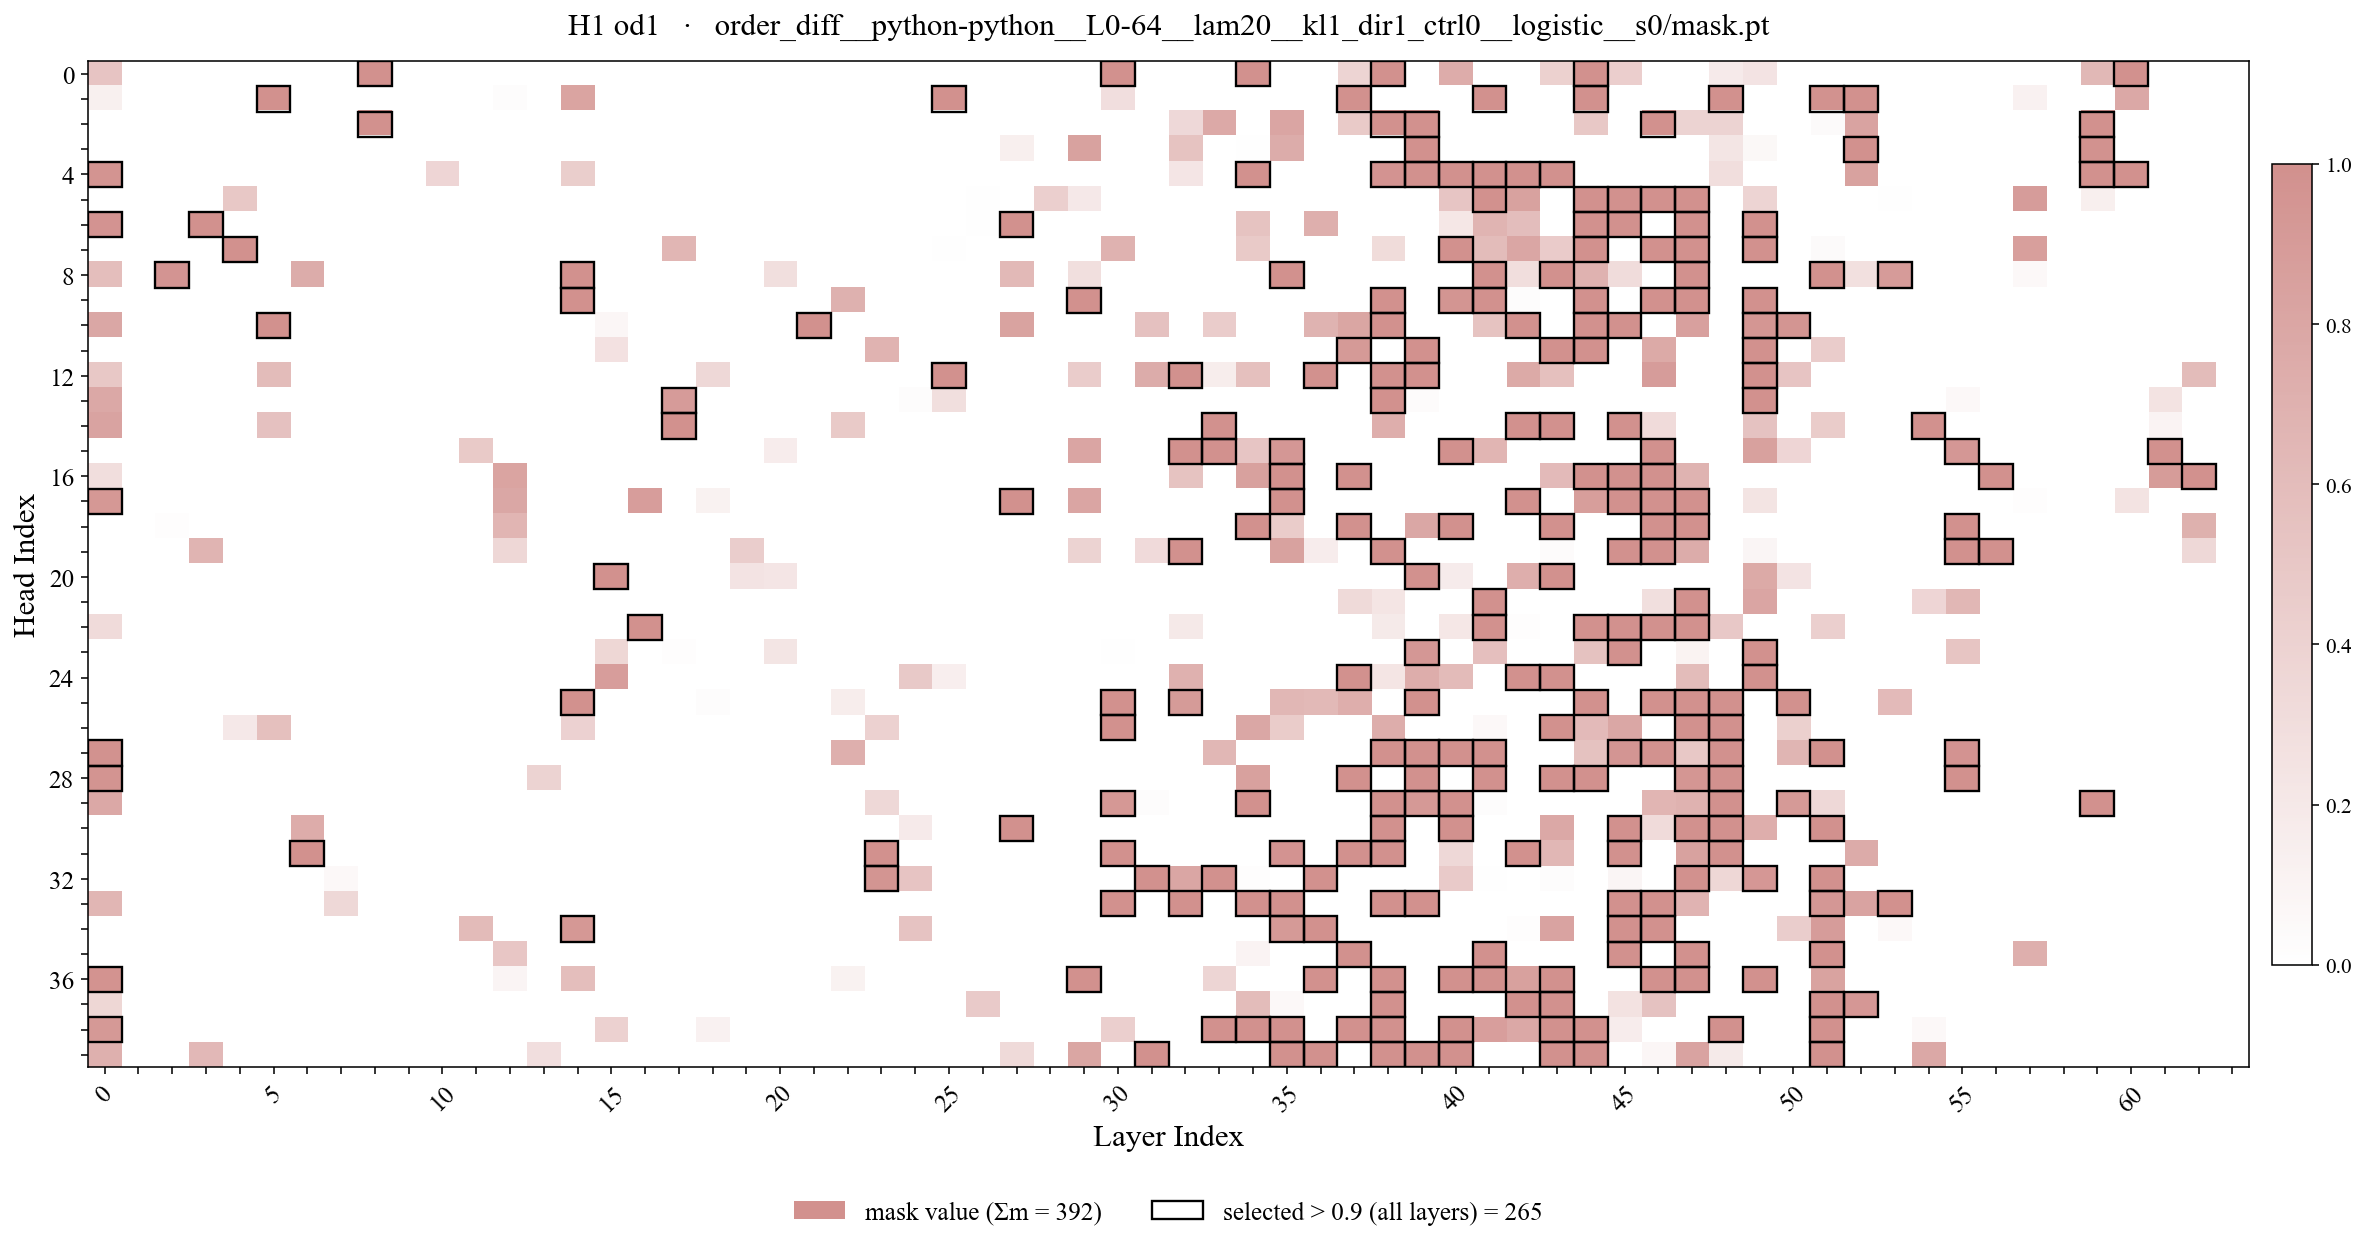

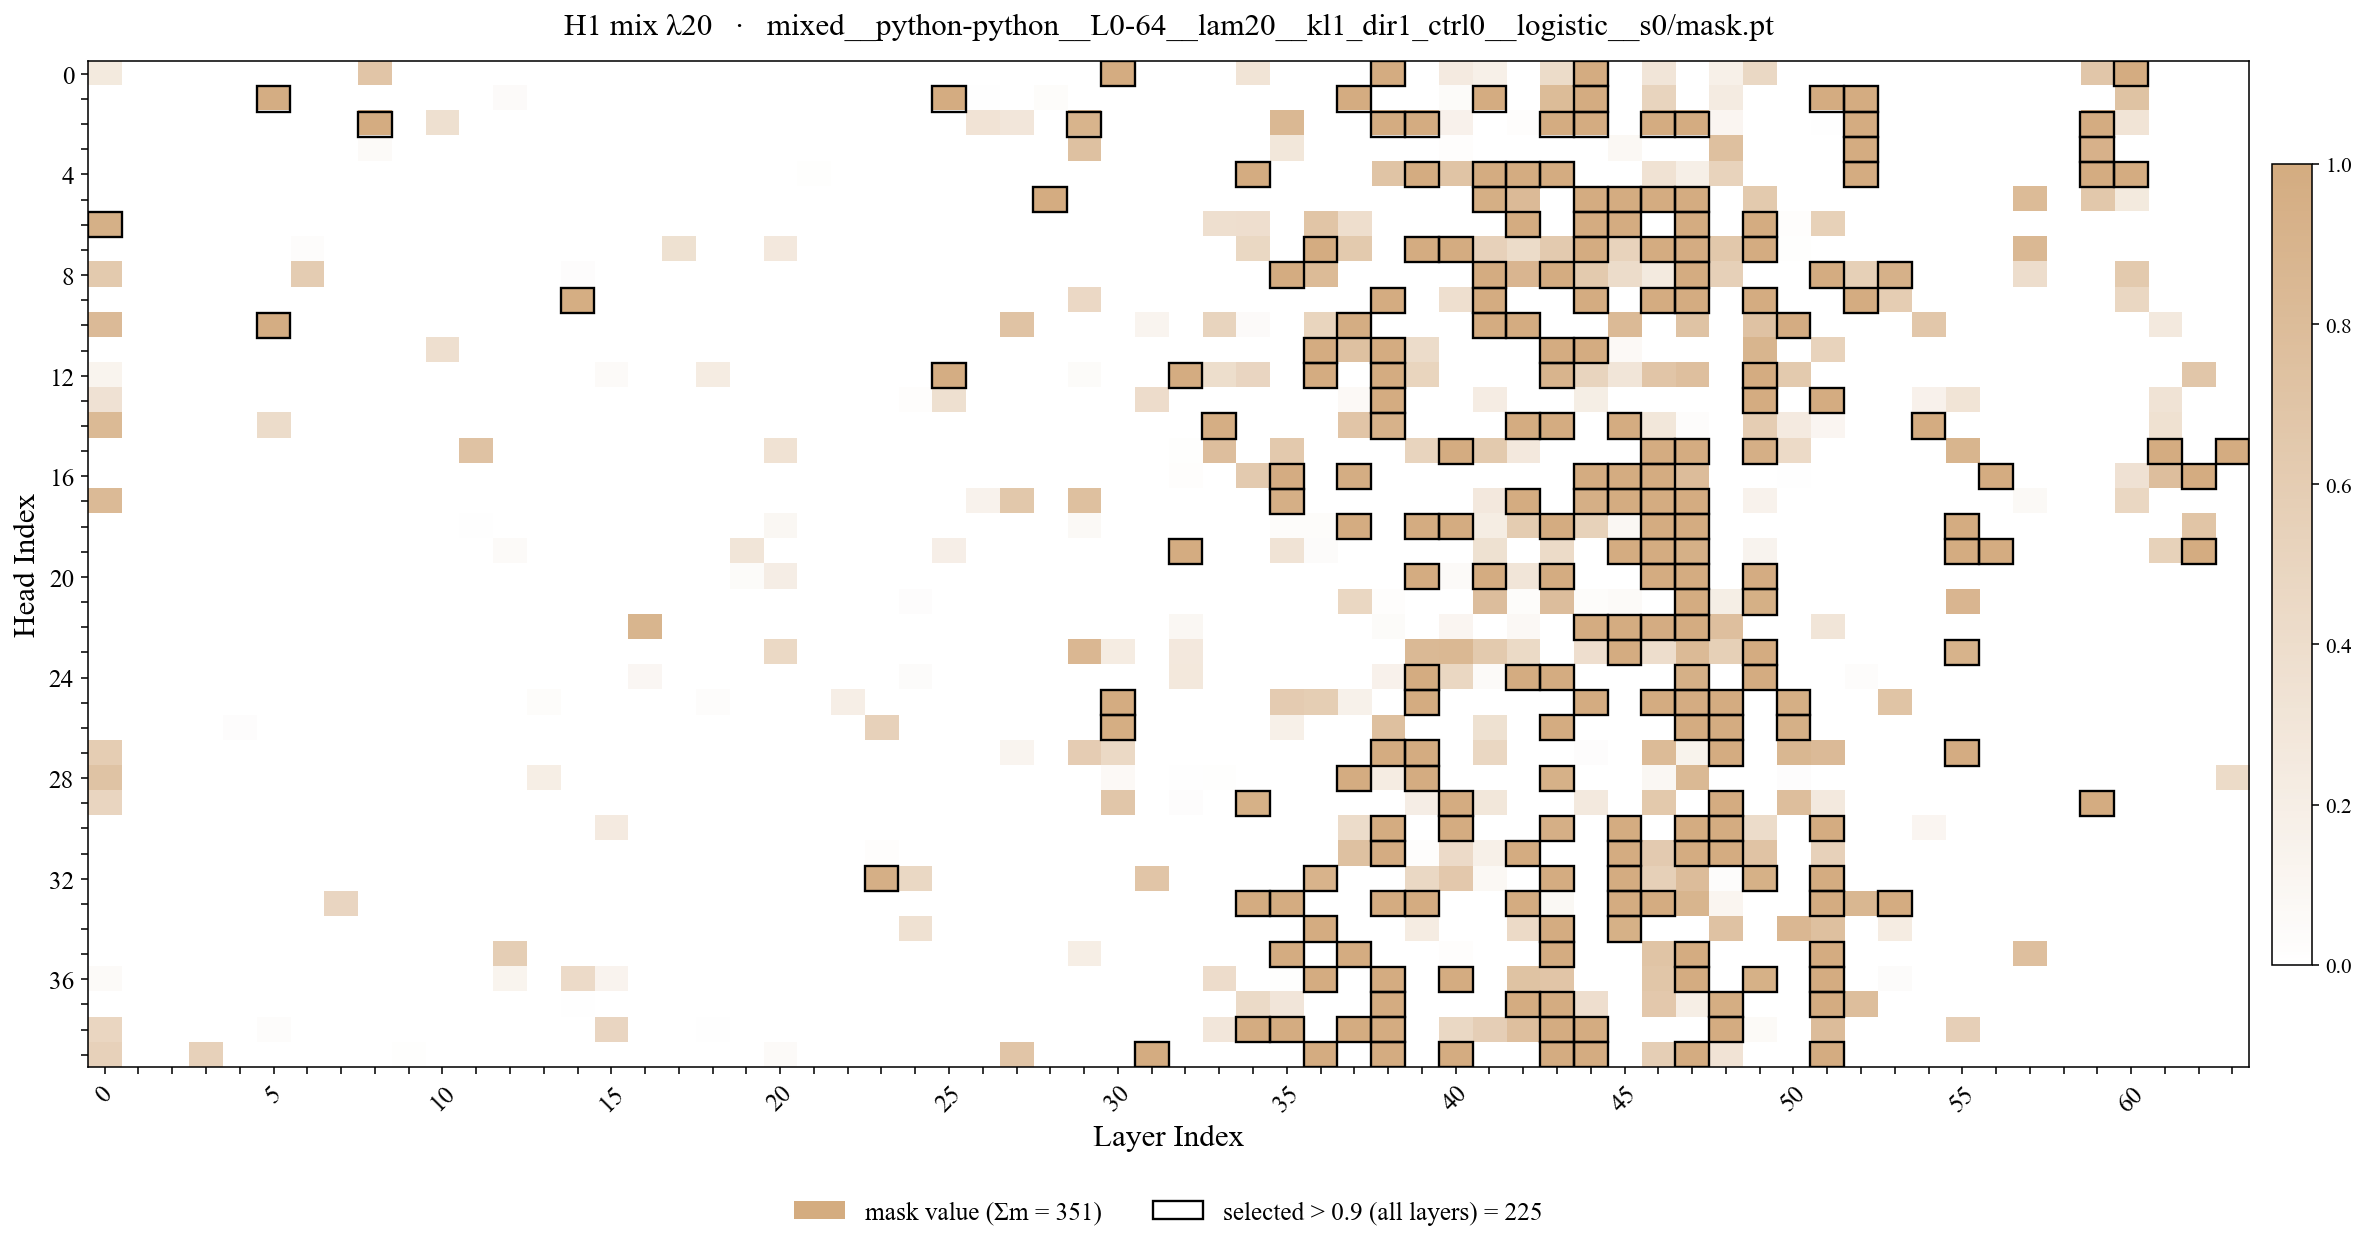

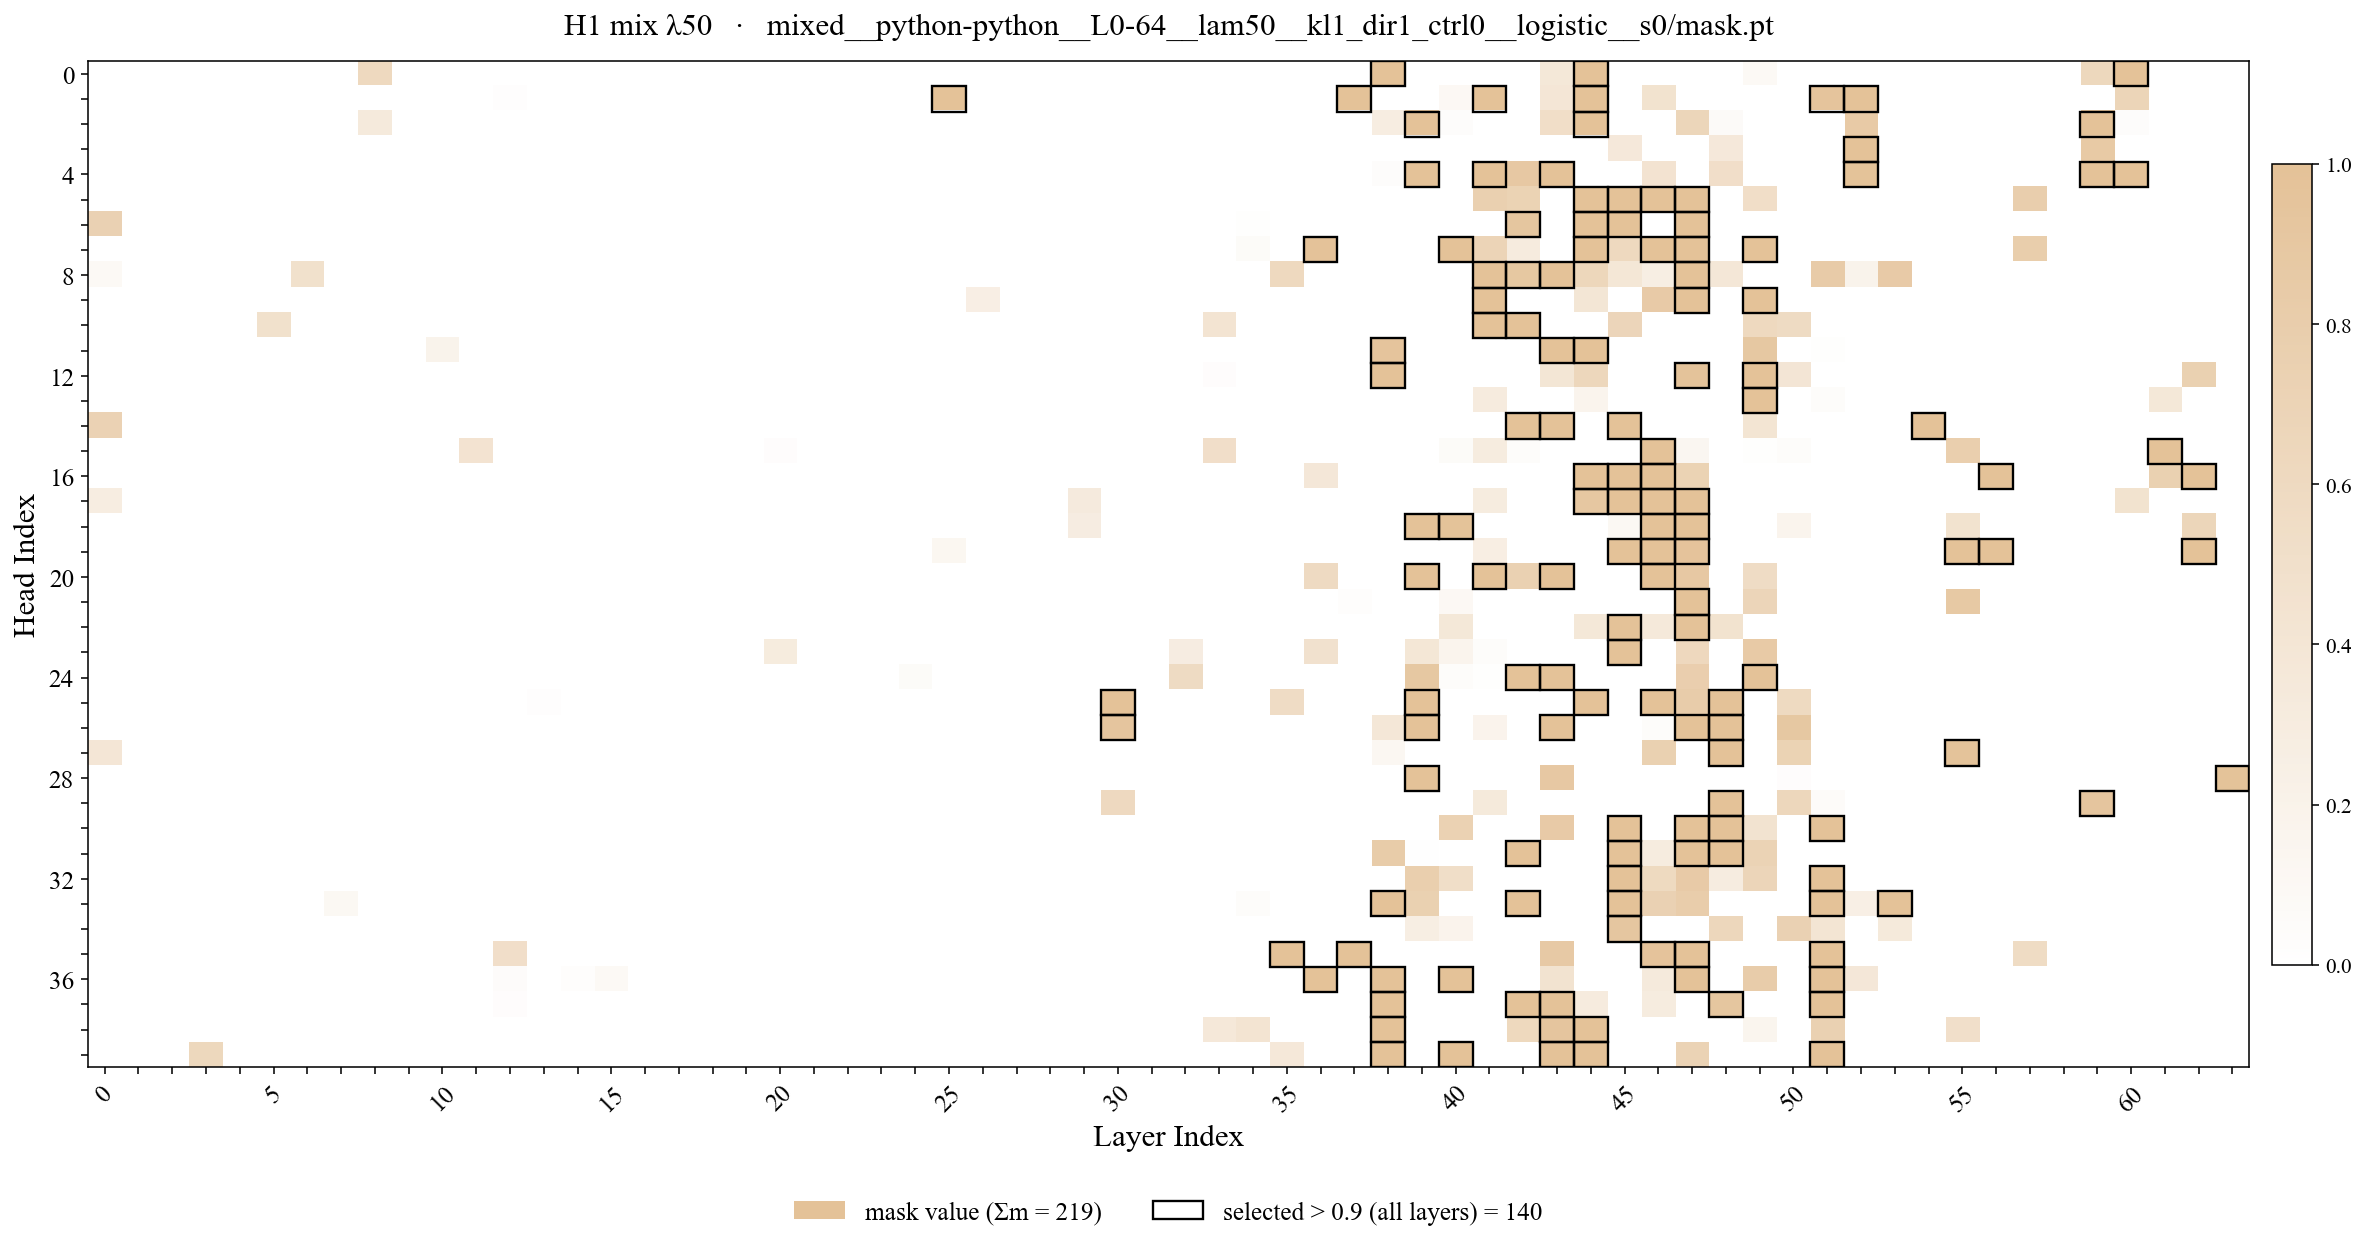

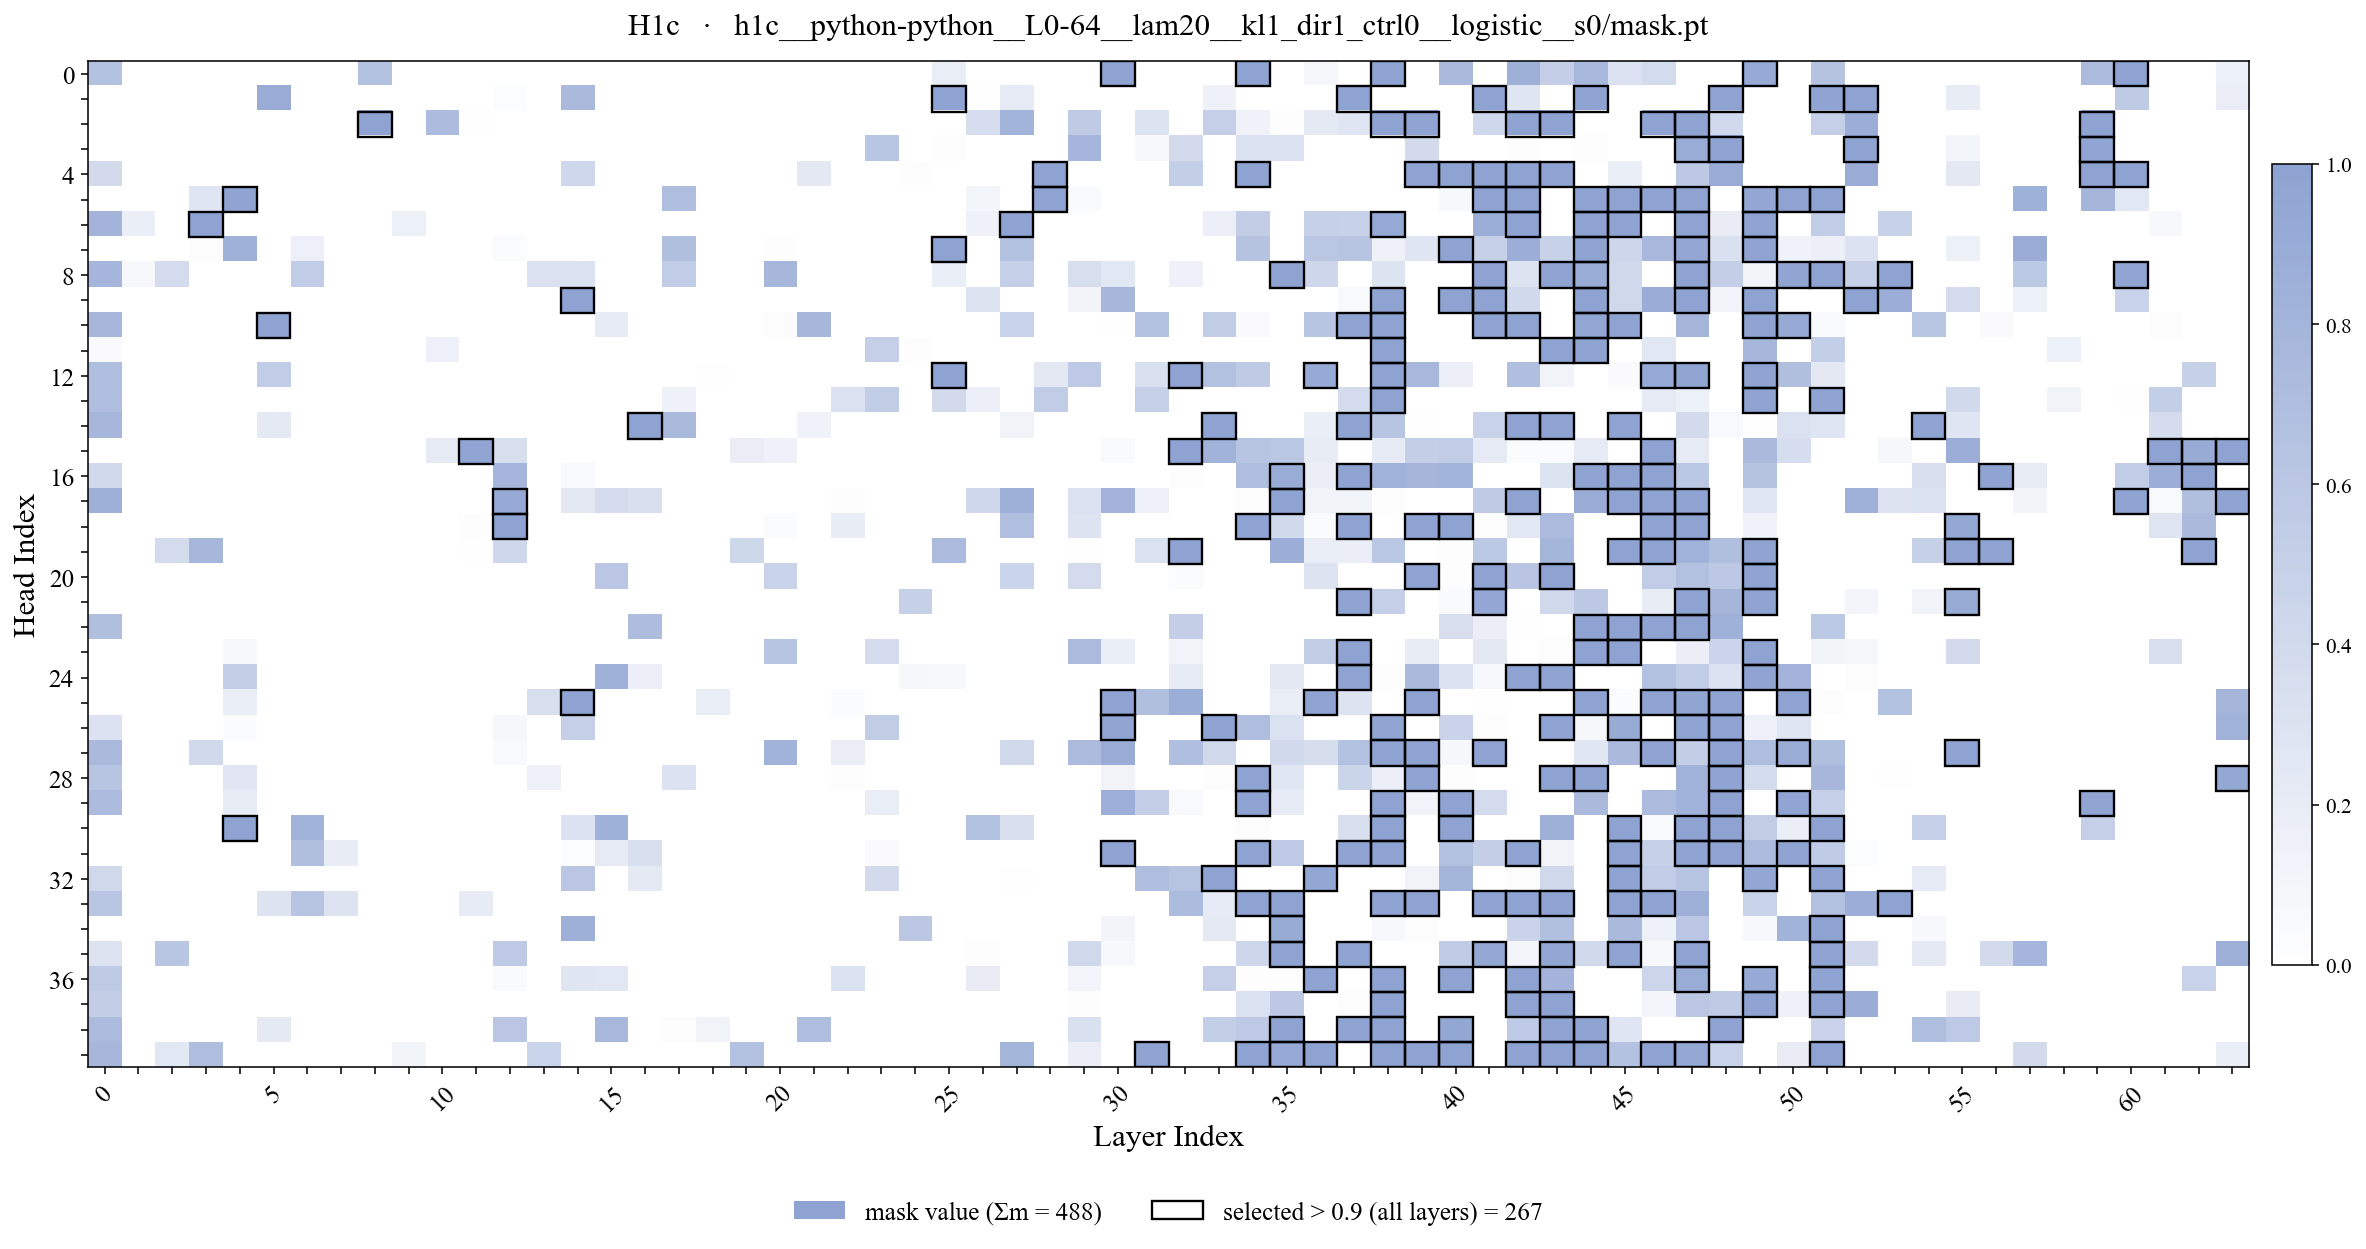

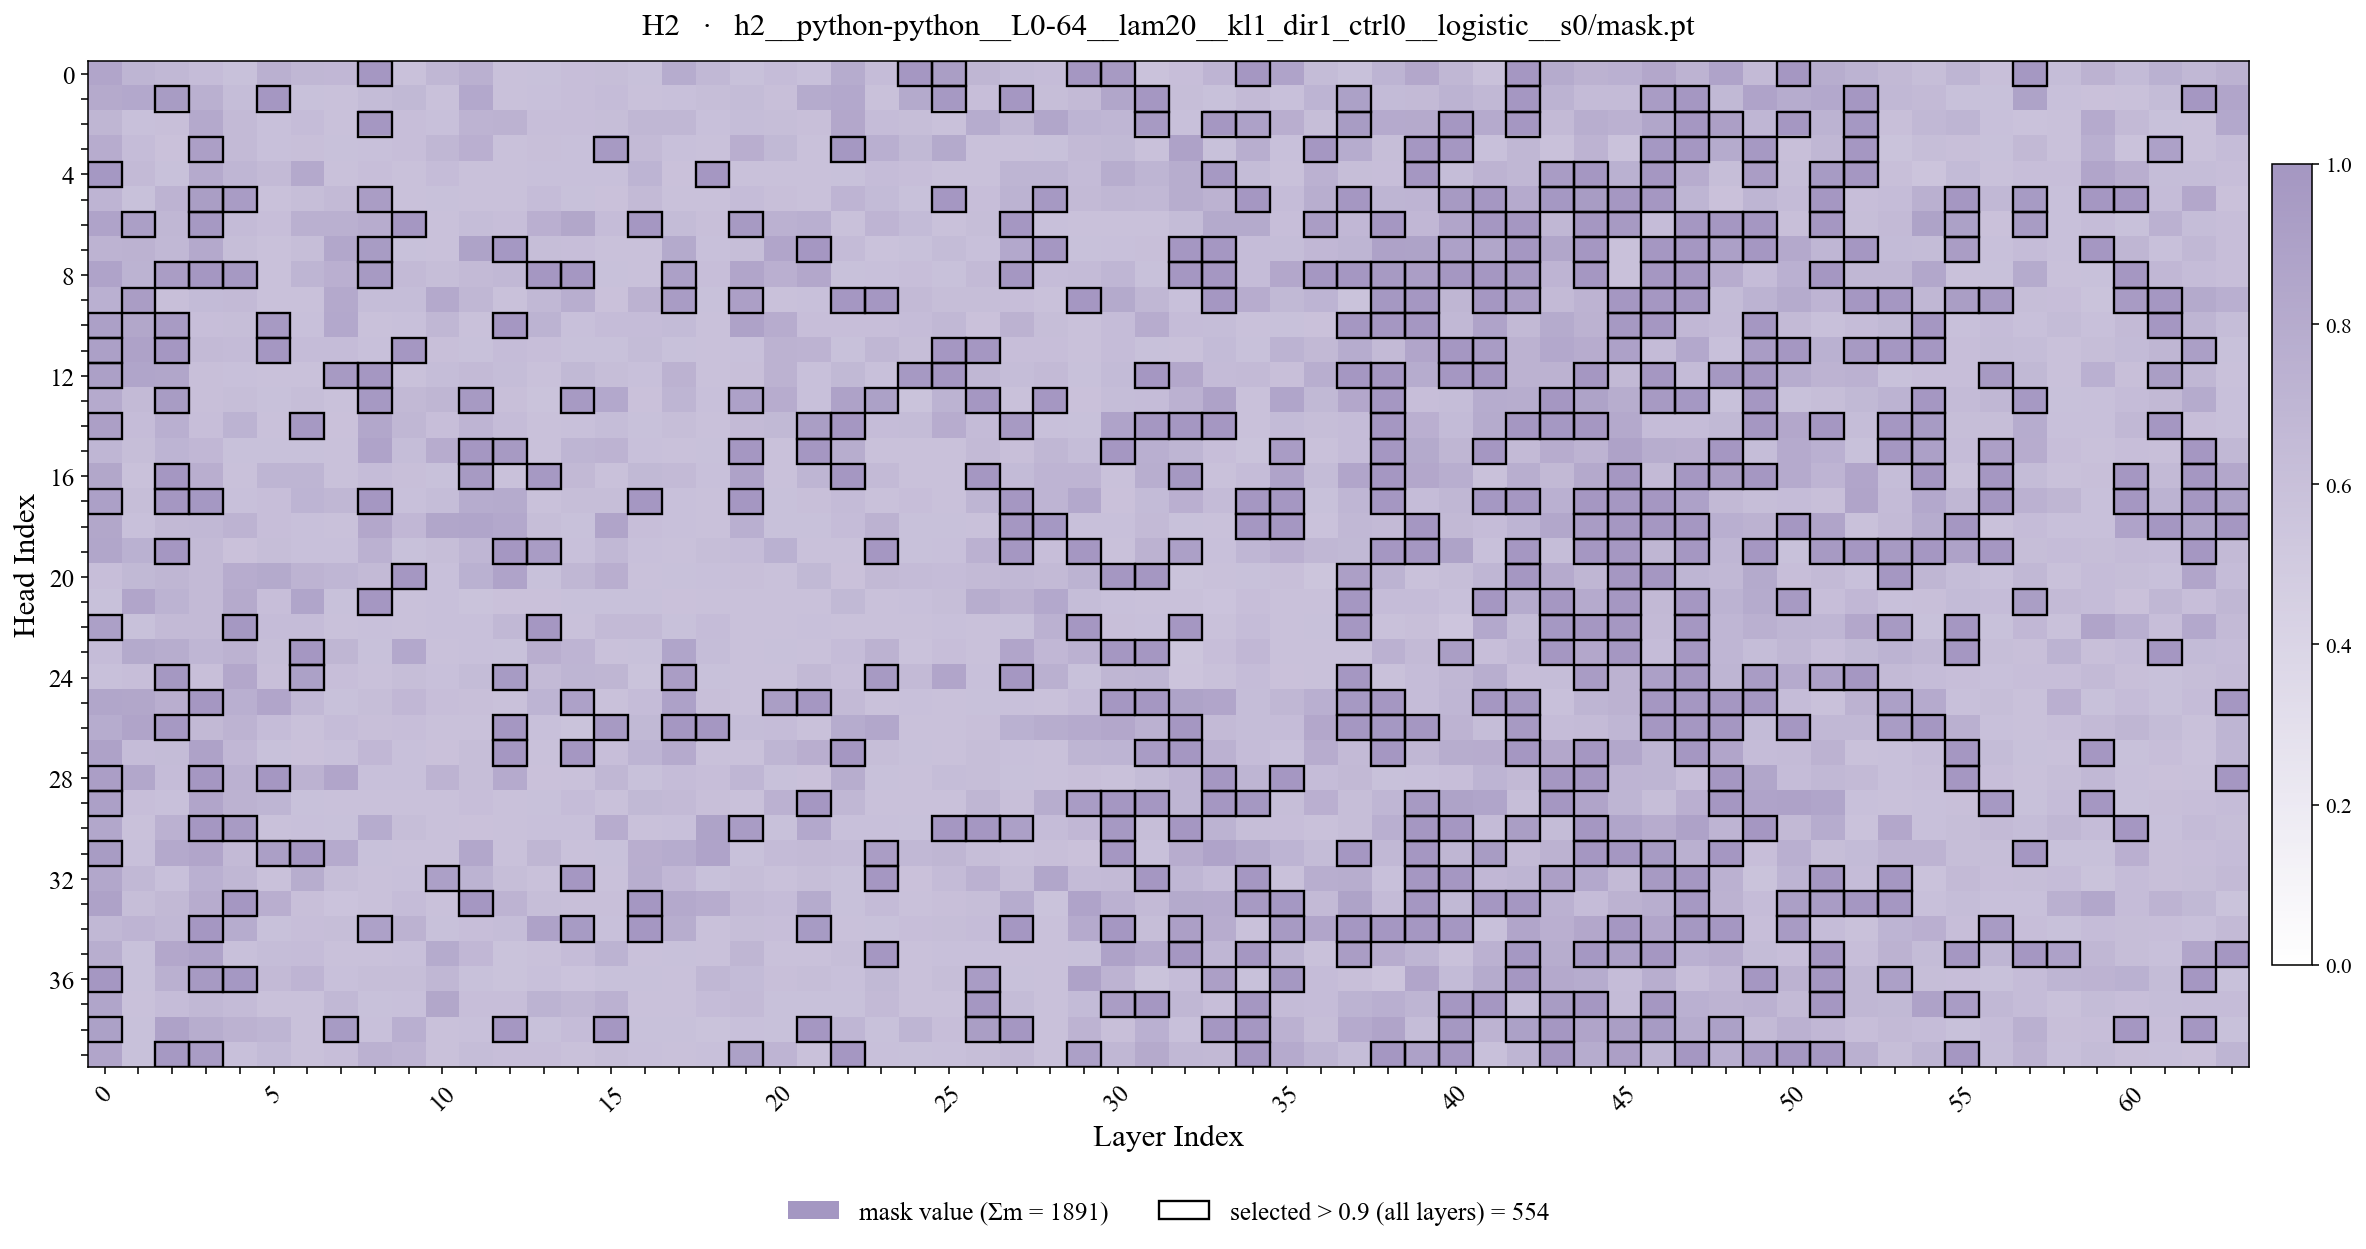

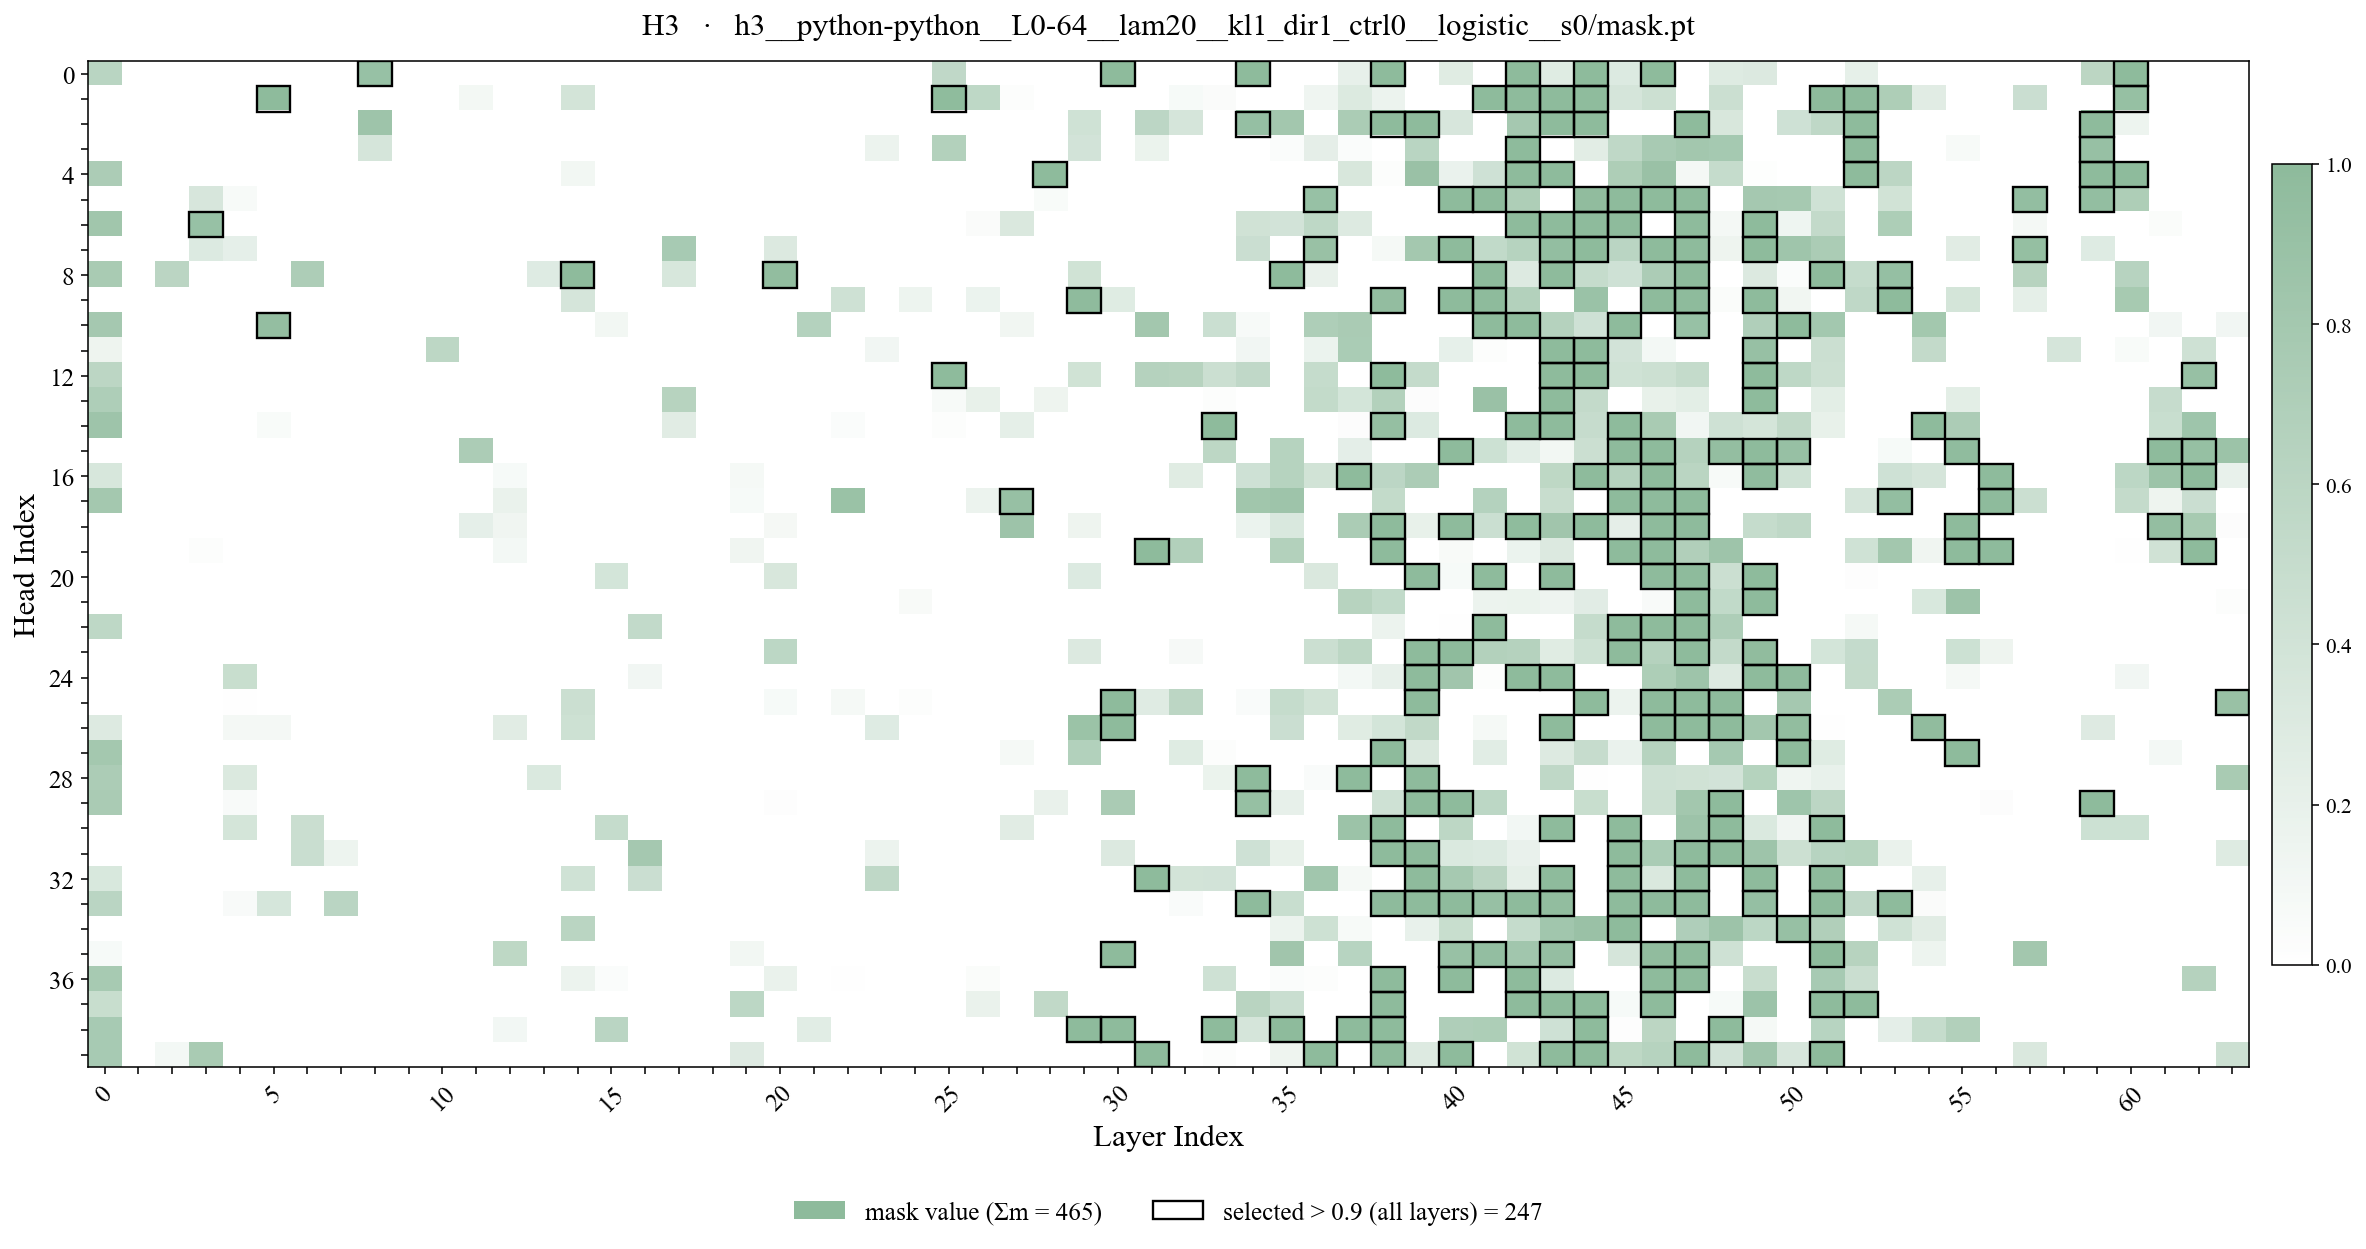

In [6]:
# ── mask landscape, one figure per run (style follows clock/__head_inspection) ──
from matplotlib.colors import LinearSegmentedColormap
from matplotlib import patches

plt.rcParams["figure.dpi"] = 140
plt.rcParams["font.family"] = "Times New Roman"
SMALL, MEDIUM, BIG = 13, 16, 19
ALPHA = 0.7

def get_ticks(n, skip=5):
    return [str(i) if i % skip == 0 else "" for i in range(n)]

def plot_head_set(hs, name=None):
    """White = 0 → the run's colour = 1; black border = selected under its cfg."""
    name = name or hs.name
    g = hs.grid.T                                     # (heads, layers): x = layer, y = head
    col = COLOR.get(name, "#BF625E")
    cmap = LinearSegmentedColormap.from_list(f"{name}_seq", ["white", col], N=256).copy()
    cmap.set_bad("#EFEFEF")
    fig, ax = plt.subplots(figsize=(17, 9))
    im = ax.imshow(np.ma.masked_invalid(g), cmap=cmap, aspect="auto", vmin=0, vmax=1, alpha=ALPHA,
                   interpolation="nearest")
    for l, h in hs.selected:
        ax.add_patch(patches.Rectangle((l - 0.5, h - 0.5), 1, 1, linewidth=1.2, edgecolor="black", facecolor="none"))
    ax.set_xticks(range(N_LAYER)); ax.set_xticklabels(get_ticks(N_LAYER, 5), rotation=45, fontsize=SMALL)
    ax.set_yticks(range(N_HEADS)); ax.set_yticklabels(get_ticks(N_HEADS, 4), fontsize=SMALL)
    ax.set_xlabel("Layer Index", fontsize=MEDIUM); ax.set_ylabel("Head Index", fontsize=MEDIUM)
    finite = hs.grid[np.isfinite(hs.grid)]
    legend = [mpatches.Patch(facecolor=col, alpha=ALPHA, label=f"mask value (Σm = {finite.sum():.0f})"),
              mpatches.Patch(facecolor="white", edgecolor="black", linewidth=1.2,
                             label=f"selected {hs.rule} = {len(hs.selected)}")]
    ax.legend(handles=legend, loc="upper center", bbox_to_anchor=(0.5, -0.11), ncol=2, fontsize=SMALL, frameon=False)
    ax.set_title(f"{name}   ·   {hs.provenance}", fontsize=BIG - 3, pad=14)
    fig.colorbar(im, ax=ax, fraction=0.018, pad=0.01).ax.tick_params(labelsize=SMALL - 2)
    plt.tight_layout(); plt.show()

for _n in HYPS:
    plot_head_set(SETS[_n])

## 2. How the mask mass is distributed — ranked values and depth

The ranked curve shows where a top-k cut would land: the flat top is the saturated block
(m = 1, `n_sat`), the long tail is the partially-weighted heads that the soft mask uses but a 0.9
threshold drops. The depth panel sums m per layer (mass, not counts).

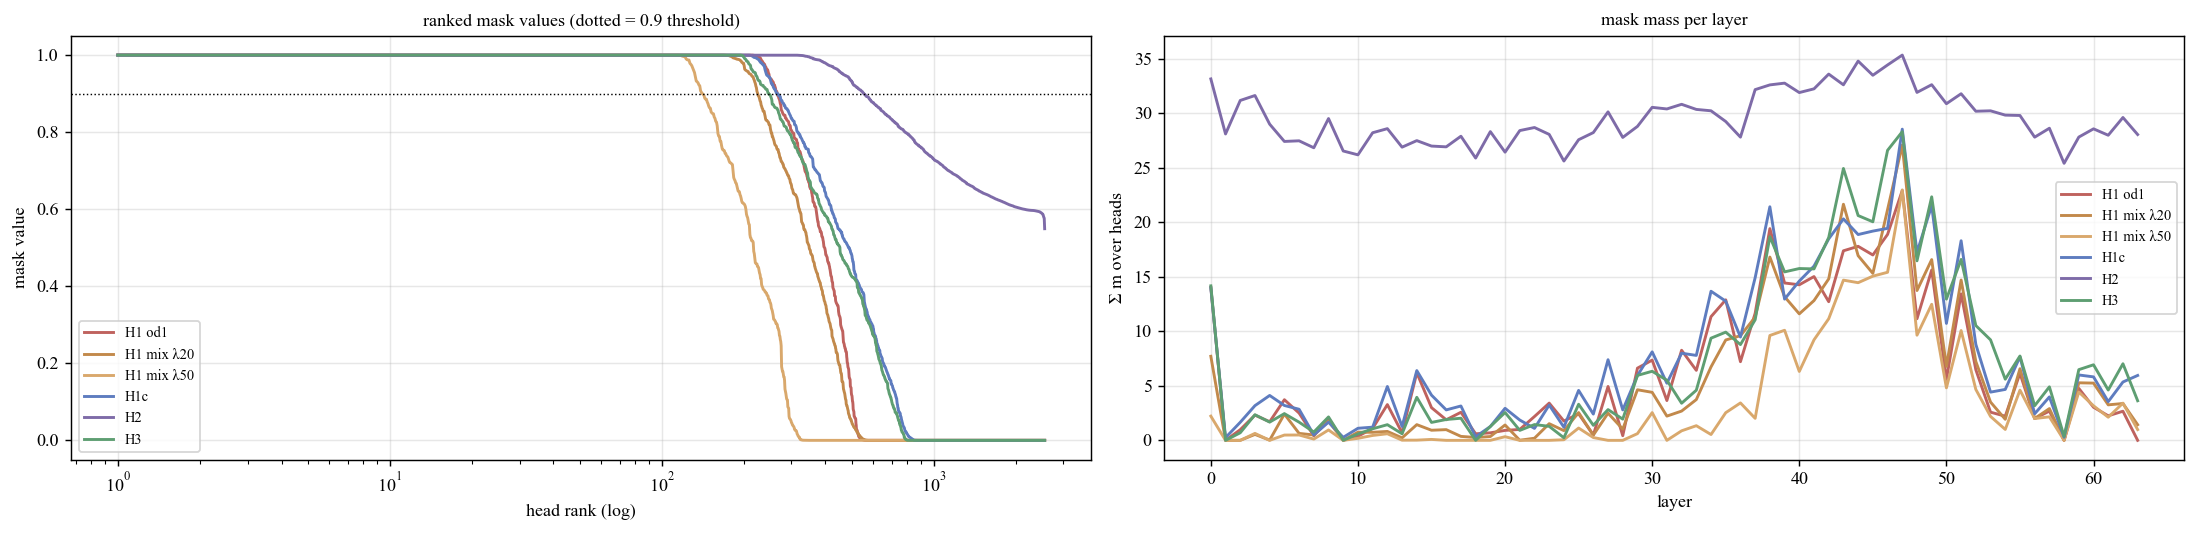

mass captured by a top-k cut                                            
                                                                        
 run          top-100 Σm   top-250 Σm   top-400 Σm   top-600 Σm   n_sat 
 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 
 H1 od1              26%          64%          92%         100%     220 
 H1 mix λ20          28%          70%          94%         100%     175 
 H1 mix λ50          46%          95%         100%         100%     117 
 H1c                 20%          51%          75%          94%     213 
 H2                   5%          13%          21%          31%     327 
 H3                  22%          53%          77%          95%     197

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(17, 4.2), dpi=130)
for n in HYPS:
    v = np.sort(SETS[n].grid[np.isfinite(SETS[n].grid)])[::-1]
    axes[0].plot(np.arange(1, v.size + 1), v, lw=1.6, color=COLOR[n], label=n)
    axes[1].plot(np.nansum(SETS[n].grid, axis=1), lw=1.6, color=COLOR[n], label=n)
axes[0].axhline(0.9, color="k", lw=0.8, ls=":"); axes[0].set_xscale("log")
axes[0].set_xlabel("head rank (log)"); axes[0].set_ylabel("mask value")
axes[0].set_title("ranked mask values (dotted = 0.9 threshold)", fontsize=10)
axes[1].set_xlabel("layer"); axes[1].set_ylabel("Σ m over heads")
axes[1].set_title("mask mass per layer", fontsize=10)
for ax in axes:
    ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

t = Table(title="mass captured by a top-k cut", box=SIMPLE_HEAVY, pad_edge=False, title_justify="left")
KS = [100, 250, 400, 600]
t.add_column("run", no_wrap=True)
for k in KS:
    t.add_column(f"top-{k} Σm", justify="right")
t.add_column("n_sat", justify="right")
for n in HYPS:
    v = np.sort(SETS[n].grid[np.isfinite(SETS[n].grid)])[::-1]
    t.add_row(n, *[f"{v[:k].sum() / v.sum():.0%}" for k in KS], str(int((v >= 0.999).sum())))
rich_print(t)

## 3. Do the hypotheses use the same heads?

Two views. **Soft-mask similarity** (cosine and Pearson over all 2,560 mask values) compares the masks
as trained, with no threshold. **Selected-set overlap** compares the selections, against a
**layer-matched null**: each set's per-layer counts are kept and heads are randomized only within a
layer (per-layer hypergeometric), so shared *depth* is not credited as shared *identity*. Read
`lift_l` / `z`, not the uniform lift. `ovlp` = |A∩B| / min(|A|, |B|) (Jaccard is capped by the size
ratio and not comparable across pairs).

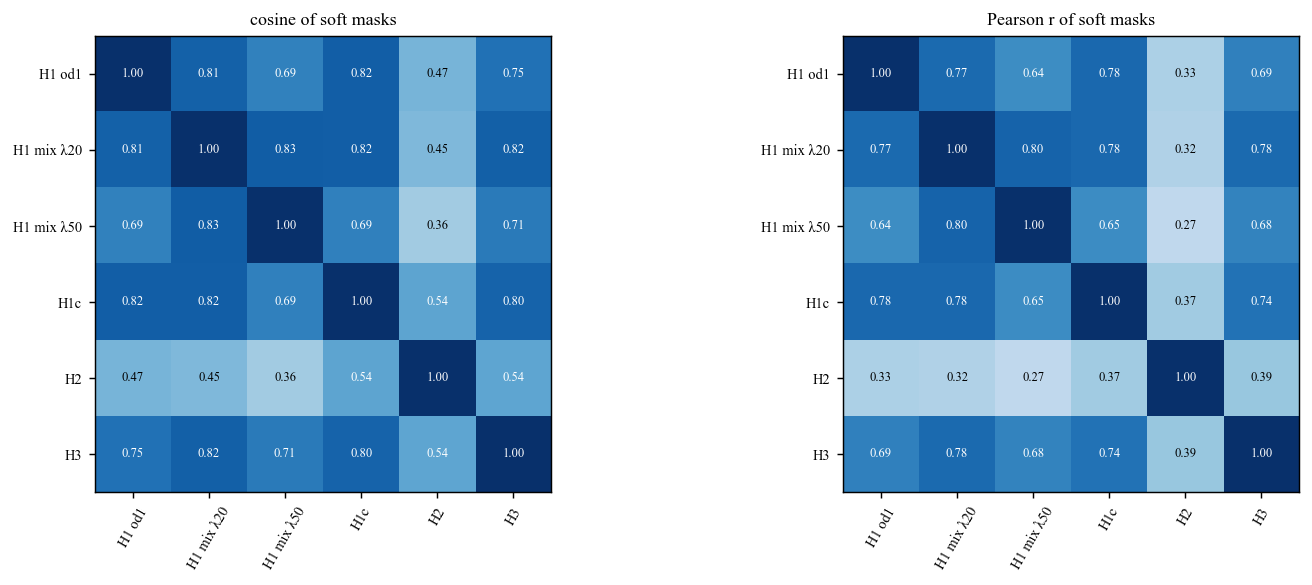

H2's mask is near-uniform (never sparsified), so its cosine with anything is high and its Pearson r is the informative number.

In [8]:
# ── soft-mask similarity ──
V = {n: np.nan_to_num(SETS[n].grid, nan=0.0).ravel() for n in HYPS}
cos = np.array([[V[a] @ V[b] / (np.linalg.norm(V[a]) * np.linalg.norm(V[b])) for b in HYPS] for a in HYPS])
pear = np.array([[np.corrcoef(V[a], V[b])[0, 1] for b in HYPS] for a in HYPS])
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), dpi=130)
for ax, M, ttl in ((axes[0], cos, "cosine of soft masks"), (axes[1], pear, "Pearson r of soft masks")):
    im = ax.imshow(M, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(len(HYPS))); ax.set_xticklabels(HYPS, rotation=60, fontsize=8)
    ax.set_yticks(range(len(HYPS))); ax.set_yticklabels(HYPS, fontsize=8)
    for r in range(len(HYPS)):
        for c_ in range(len(HYPS)):
            ax.text(c_, r, f"{M[r, c_]:.2f}", ha="center", va="center", fontsize=7,
                    color="white" if M[r, c_] > 0.5 else "black")
    ax.set_title(ttl, fontsize=10)
plt.tight_layout(); plt.show()
rich_print("[grey58]H2's mask is near-uniform (never sparsified), so its cosine with anything is high "
           "and its Pearson r is the informative number.[/grey58]")

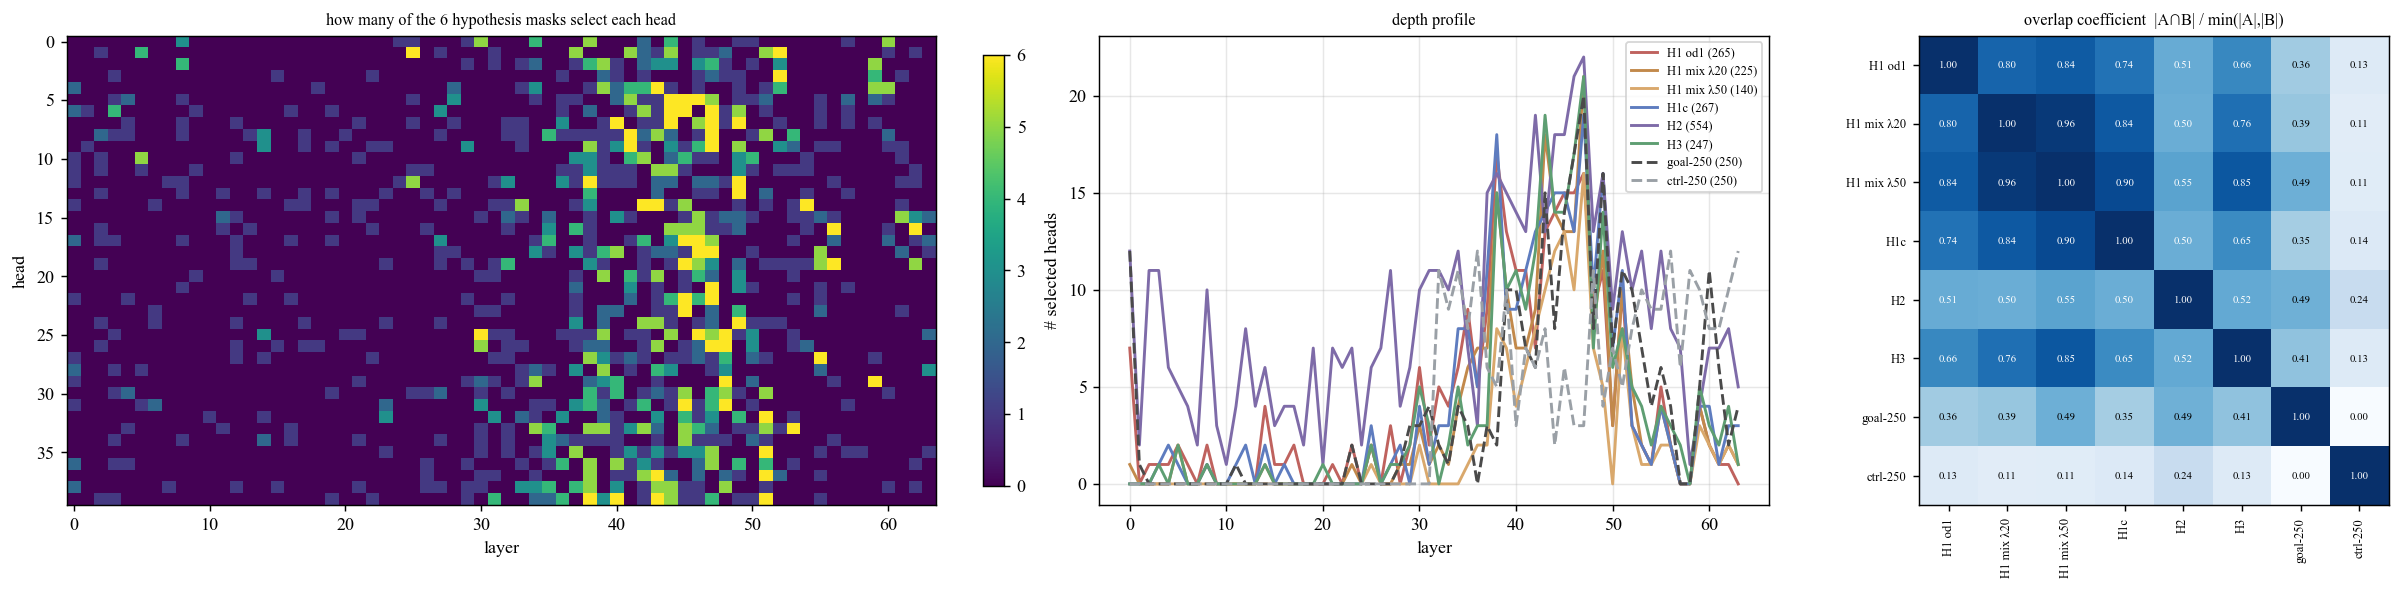

                selected-set overlap — uniform vs layer-matched null                
┏━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━┳━━━━━┳━━━━━┳━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━━┳━━━━━━┓
┃pair                    ┃ |A| ┃ |B| ┃ |∩| ┃ ovlp ┃ lift_u ┃ E_lay ┃ lift_l ┃     z┃
┡━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━╇━━━━━╇━━━━━╇━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━━╇━━━━━━┩
│H1 mix λ20 ∩ H1 mix λ50 │ 225 │ 140 │ 135 │ 0.96 │ 10.97x │  40.1 │  3.36x │ +21.1│
│H1 od1 ∩ H1 mix λ20     │ 265 │ 225 │ 180 │ 0.80 │  7.73x │  59.3 │  3.03x │ +22.5│
│H1 od1 ∩ H1c            │ 265 │ 267 │ 197 │ 0.74 │  7.13x │  65.9 │  2.99x │ +23.3│
│H1 mix λ20 ∩ H1c        │ 225 │ 267 │ 189 │ 0.84 │  8.05x │  63.7 │  2.97x │ +23.1│
│H1 mix λ50 ∩ H1c        │ 140 │ 267 │ 126 │ 0.90 │  8.63x │  42.6 │  2.96x │ +18.0│
│H1 od1 ∩ H1 mix λ50     │ 265 │ 140 │ 117 │ 0.84 │  8.07x │  39.6 │  2.95x │ +17.0│
│H1 mix λ50 ∩ H3         │ 140 │ 247 │ 119 │ 0.85 │  8.81x │  42.7 │  2.79x │ +16.7│
│H1 mix λ20 ∩ H3         │ 225 │ 247 │ 170 │ 0.76 │  7.83x │  62.0 │  2.74x │ +20.6│
│H1 od1 ∩ H3             │ 265 │ 247 │ 164 │ 0.66 │  6.41x │  62.2 │  2.64x │ +18.9│
│H1c ∩ H3                │ 267 │ 247 │ 161 │ 0.65 │  6.25x │  67.2 │  2.40x │ +17.1│
│H1 mix λ50 ∩ goal-250   │ 140 │ 250 │  69 │ 0.49 │  5.05x │  37.1 │  1.86x │  +7.3│
│H3 ∩ goal-250           │ 247 │ 250 │ 101 │ 0.41 │  4.19x │  59.0 │  1.71x │  +8.0│
│H1 od1 ∩ goal-250       │ 265 │ 250 │  91 │ 0.36 │  3.52x │  55.3 │  1.65x │  +6.8│
│H1 mix λ20 ∩ goal-250   │ 225 │ 250 │  88 │ 0.39 │  4.00x │  53.5 │  1.64x │  +6.8│
│H1c ∩ goal-250          │ 267 │ 250 │  88 │ 0.35 │  3.37x │  57.6 │  1.53x │  +5.8│
│H1 od1 ∩ H2             │ 265 │ 554 │ 135 │ 0.51 │  2.35x │  90.3 │  1.49x │  +6.9│
│H2 ∩ H3                 │ 554 │ 247 │ 129 │ 0.52 │  2.41x │  88.3 │  1.46x │  +6.6│
│H2 ∩ goal-250           │ 554 │ 250 │ 123 │ 0.49 │  2.27x │  84.5 │  1.45x │  +6.2│
│H1c ∩ H2                │ 267 │ 554 │ 134 │ 0.50 │  2.32x │  92.9 │  1.44x │  +6.4│
│H1 mix λ50 ∩ H2         │ 140 │ 554 │  77 │ 0.55 │  2.54x │  53.7 │  1.43x │  +4.7│
│H1 mix λ20 ∩ H2         │ 225 │ 554 │ 113 │ 0.50 │  2.32x │  80.5 │  1.40x │  +5.5│
│H2 ∩ ctrl-250           │ 554 │ 250 │  59 │ 0.24 │  1.09x │  63.4 │  0.93x │  -0.7│
│H1 od1 ∩ ctrl-250       │ 265 │ 250 │  32 │ 0.13 │  1.24x │  35.9 │  0.89x │  -0.8│
│H3 ∩ ctrl-250           │ 247 │ 250 │  31 │ 0.13 │  1.29x │  35.1 │  0.88x │  -0.9│
│H1c ∩ ctrl-250          │ 267 │ 250 │  34 │ 0.14 │  1.30x │  39.1 │  0.87x │  -1.0│
│H1 mix λ50 ∩ ctrl-250   │ 140 │ 250 │  16 │ 0.11 │  1.17x │  20.6 │  0.78x │  -1.2│
│H1 mix λ20 ∩ ctrl-250   │ 225 │ 250 │  25 │ 0.11 │  1.14x │  33.3 │  0.75x │  -1.8│
│goal-250 ∩ ctrl-250     │ 250 │ 250 │   0 │ 0.00 │  0.00x │  36.8 │  0.00x │  -7.7│
└────────────────────────┴─────┴─────┴─────┴──────┴────────┴───────┴────────┴──────┘

In [9]:
# ── selected-set overlap vs a layer-matched null ──
names = list(SETS)
PROF = {n: np.bincount([l for l, _ in SETS[n].selected], minlength=N_LAYER) for n in names}

def overlap_stats(a, b):
    """|A∩B| against a uniform null (E = |A||B|/N) and a layer-matched one (sum of per-layer
    Hypergeometric(H, a_l, b_l) means / variances — layers independent)."""
    A, B = SETS[a].key, SETS[b].key
    i = len(A & B)
    e_u = len(A) * len(B) / (N_LAYER * N_HEADS)
    al, bl, H = PROF[a].astype(float), PROF[b].astype(float), N_HEADS
    e_l = float((al * bl / H).sum())
    var = float((bl * (al / H) * ((H - al) / H) * ((H - bl) / (H - 1))).sum())
    return dict(i=i, nA=len(A), nB=len(B), jac=i / len(A | B) if A | B else 0.0,
                ovl=i / min(len(A), len(B)) if A and B else 0.0, e_u=e_u, lift_u=i / e_u if e_u else np.nan,
                e_l=e_l, lift_l=i / e_l if e_l else np.nan, z=(i - e_l) / np.sqrt(var) if var > 0 else np.nan)

STATS = {(a, b): overlap_stats(a, b) for a, b in itertools.combinations(names, 2)}
cover = np.zeros((N_LAYER, N_HEADS))
for n in HYPS:
    for l, h in SETS[n].selected:
        cover[l, h] += 1

fig, axes = plt.subplots(1, 3, figsize=(19, 4.6), dpi=130, gridspec_kw={"width_ratios": [2.1, 1.5, 1.3]})
im = axes[0].imshow(cover.T, aspect="auto", cmap="viridis", vmin=0, vmax=max(1, cover.max()), interpolation="nearest")
axes[0].set_title(f"how many of the {len(HYPS)} hypothesis masks select each head", fontsize=9)
axes[0].set_xlabel("layer"); axes[0].set_ylabel("head"); fig.colorbar(im, ax=axes[0], fraction=0.023)
for n in names:
    axes[1].plot(PROF[n], lw=1.6, color=COLOR.get(n), ls="--" if n in REF else "-", label=f"{n} ({len(SETS[n].selected)})")
axes[1].set_xlabel("layer"); axes[1].set_ylabel("# selected heads"); axes[1].set_title("depth profile", fontsize=9)
axes[1].grid(alpha=0.3); axes[1].legend(fontsize=7)
M = np.eye(len(names))
for (a, b), s in STATS.items():
    M[names.index(a), names.index(b)] = M[names.index(b), names.index(a)] = s["ovl"]
im = axes[2].imshow(M, cmap="Blues", vmin=0, vmax=1)
axes[2].set_xticks(range(len(names))); axes[2].set_xticklabels(names, rotation=90, fontsize=7)
axes[2].set_yticks(range(len(names))); axes[2].set_yticklabels(names, fontsize=7)
for r in range(len(names)):
    for c_ in range(len(names)):
        axes[2].text(c_, r, f"{M[r, c_]:.2f}", ha="center", va="center", fontsize=6, color="white" if M[r, c_] > 0.5 else "black")
axes[2].set_title("overlap coefficient  |A∩B| / min(|A|,|B|)", fontsize=9)
plt.tight_layout(); plt.show()

t = Table(title="selected-set overlap — uniform vs layer-matched null", pad_edge=False)
t.add_column("pair", no_wrap=True)
for c_ in ["|A|", "|B|", "|∩|", "ovlp", "lift_u", "E_lay", "lift_l", "z"]:
    t.add_column(c_, justify="right", no_wrap=True)
for (a, b), s in sorted(STATS.items(), key=lambda kv: -kv[1]["lift_l"]):
    t.add_row(f"{a} ∩ {b}", str(s["nA"]), str(s["nB"]), str(s["i"]), f"{s['ovl']:.2f}", f"{s['lift_u']:.2f}x",
              f"{s['e_l']:.1f}", f"{s['lift_l']:.2f}x", f"{s['z']:+.1f}")
rich_print(t)

## 4. Re-select and export

A different selection rule per run (e.g. top-k instead of the 0.9 threshold, which drops the
partially-weighted tail). `SELECT` is independent of `CFG` so §1–3 do not change. The filename carries
the rule — downstream evals key their run dir on the head-set file **stem**, so two selections must
never share one. `SAVE_JSON = False` by default.

In [10]:
SELECT = {                                   # name -> list of selection cfgs (run taken from CFG)
    "H1c": [dict(threshold=None, topk=k, band=None) for k in (250, 400)],
    "H3":  [dict(threshold=None, topk=k, band=None) for k in (250, 400)],
}
SAVE_JSON = False
EXPORT_DIR = REPO / "head_sets" / SLUG / "nrgs_hyp_topk"

def export_name(name, hs):
    c = hs.cfg
    rule = (f"top{c['topk']}" if c.get("topk") is not None else
            f"thr{c['threshold']:g}" + (f"_band{c['band'][0]}-{c['band'][1]}" if c.get("band") else ""))
    label = name.lower().replace(" ", "-").replace("λ", "lam")
    return EXPORT_DIR / f"hyp-{label}-{rule}__{c['run'].split('__')[0]}_{rule}.json"

t = Table(title="re-selections", box=SIMPLE_HEAVY, pad_edge=False, title_justify="left")
for c_ in ["run", "rule", "n", "m at cut", "n_tied@cut", "Σm kept", "layers", "top layers", "∩ goal-250", "file"]:
    t.add_column(c_, justify="left" if c_ in ("run", "rule", "top layers", "file") else "right", no_wrap=True)
written = []
for name, cfgs in SELECT.items():
    for sc in cfgs:
        hs = load_mask(name, dict(sc, run=CFG[name]["run"]))
        v = np.sort(hs.grid[np.isfinite(hs.grid)])[::-1]
        k = len(hs.selected)
        at = v[k - 1] if 0 < k <= v.size else np.nan
        ls = [l for l, _ in hs.selected]
        p = export_name(name, hs)
        if SAVE_JSON:
            p.parent.mkdir(parents=True, exist_ok=True)
            p.write_text(json.dumps([[int(l), int(h)] for l, h in sorted(hs.selected)]))
            written.append(p)
        t.add_row(name, hs.rule, str(k), f"{at:.3f}", str(int((v == at).sum())), f"{v[:k].sum() / v.sum():.0%}",
                  f"{min(ls)}-{max(ls)}", " ".join(f"L{l}:{c}" for l, c in Counter(ls).most_common(3)),
                  str(len(hs.key & SETS['goal-250'].key)) if "goal-250" in SETS else "—",
                  p.name if SAVE_JSON else "(not written)")
rich_print(t)
for p in written:
    rich_print(f"  [green]{len(json.loads(p.read_text())):4d}[/green] heads -> {p}")

re-selections                                                                                                                
                                                                                                                             
 run   rule                 n   m at cut   n_tied@cut   Σm kept   layers   top layers             ∩ goal-250   file          
 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 
 H1c   top-250 (global)   250      0.942            1       51%     3-63   L38:17 L47:17 L43:14           85   (not written) 
 H1c   top-400 (global)   400      0.643            1       75%     0-63   L47:25 L49:21 L38:19          113   (not written) 
 H3    top-250 (global)   250      0.897            1       53%     3-63   L47:21 L43:19 L46:18          103   (not written) 
 H3    top-400 (global)   400      0.583            1       77%     0-63   L47:29 L46:27 L43:22          145   (not written)